This notebook explores and prepares the dataset for predicting dairy cow milk yield using dry matter intake (DMI), THI Range and Genetic Group. It includes data quality checks, exploratory data analysis, feature selection and preparation of the final dataset for modelling.

In [1]:
import pandas as pd

df = pd.read_excel("milk yield and composition.xlsx")

df.head()

,Animal ID,Genetic Group,THI Range,Replication No,DMI (kg),Milk Yield (L/day/cow),SCC cells per mL,Fat%,SNF%,Protein %,Salt%,Lactose%,pH
0,102,Local,T0,1,6.91,2.05,138000,3.91,9.85,3.40,0.746,5.24,7.02
1,102,Local,T0,2,6.61,1.14,146000,3.72,8.68,3.54,0.746,5.06,6.91
2,102,Local,T0,3,7.31,1.74,122000,3.93,8.76,3.44,0.712,4.90,6.99
3,102,Local,T0,4,6.75,1.96,110000,3.87,9.09,3.37,0.763,5.18,7.03
4,102,Local,T0,5,6.42,2.24,164000,3.82,9.65,3.45,0.738,5.10,7.06


## Missing Records
All 750 records contain values in the dataset's 13 columns. No missing values were identified, so removal of records due to missing data was unnecessary.

In [2]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values per column:
Animal ID                 0
Genetic Group             0
THI Range                 0
Replication No            0
DMI (kg)                  0
Milk Yield (L/day/cow)    0
SCC cells per mL          0
Fat%                      0
SNF%                      0
Protein %                 0
Salt%                     0
Lactose%                  0
pH                        0
dtype: int64

Total missing values: 0


## Duplicate Records

The dataset contains no duplicate rows. Therefore, no records were removed due to duplication.

In [3]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Animal ID               750 non-null    int64  
 1   Genetic Group           750 non-null    object 
 2   THI Range               750 non-null    object 
 3   Replication No          750 non-null    int64  
 4   DMI (kg)                750 non-null    float64
 5   Milk Yield (L/day/cow)  750 non-null    float64
 6   SCC cells per mL        750 non-null    int64  
 7   Fat%                    750 non-null    float64
 8   SNF%                    750 non-null    float64
 9   Protein %               750 non-null    float64
 10  Salt%                   750 non-null    float64
 11  Lactose%                750 non-null    float64
 12  pH                      750 non-null    float64
dtypes: float64(8), int64(3), object(2)
memory usage: 76.3+ KB


## Descriptive
Dry matter intake (DMI) ranges from 4.48 to 14.82 kg, while milk yield ranges from 0.30 to 10.47 litres per cow per day. These values provide an initial understanding of the data and help identify values that may require further investigation

In [5]:
df.describe()

,Animal ID,Replication No,DMI (kg),Milk Yield (L/day/cow),SCC cells per mL,Fat%,SNF%,Protein %,Salt%,Lactose%,pH
count,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000
mean,306.500000,3.000000,10.049600,5.529413,218884.000000,3.564587,8.445160,3.096093,0.688929,4.641533,6.909853
std,141.544916,1.415157,2.462994,2.572433,48790.783947,0.281956,0.686292,0.210662,0.043749,0.310787,0.096147
min,102.000000,1.000000,4.480000,0.300000,97000.000000,2.870000,6.330000,2.460000,0.589000,3.700000,6.670000
25%,204.000000,2.000000,8.800000,4.455000,185000.000000,3.362500,7.960000,2.960000,0.656250,4.420000,6.850000
50%,306.500000,3.000000,10.150000,5.805000,217500.000000,3.560000,8.420000,3.090000,0.687000,4.620000,6.900000
75%,409.000000,4.000000,11.885000,7.175000,253000.000000,3.780000,8.887500,3.230000,0.717000,4.860000,6.980000
max,511.000000,5.000000,14.820000,10.470000,364000.000000,4.310000,10.380000,3.600000,0.820000,5.500000,7.160000


## Categorical Data
The Genetic Group column contains five categories: Local, HF50, HF62.5, HF75 and HF87.5. The THI Range column contains T0, T1 and T2.

In [6]:
print("Genetic Groups:")
print(df["Genetic Group"].value_counts())

print("\nTHI Ranges:")
print(df["THI Range"].value_counts())

print("\nUnique genetic groups:")
print(df["Genetic Group"].unique())

print("\nUnique THI ranges:")
print(df["THI Range"].unique())

Genetic Groups:
Genetic Group
Local     150
HF50      150
HF62.5    150
HF75      150
HF87.5    150
Name: count, dtype: int64

THI Ranges:
THI Range
T0    250
T1    250
T2    250
Name: count, dtype: int64

Unique genetic groups:
['Local' 'HF50' 'HF62.5' 'HF75' 'HF87.5']

Unique THI ranges:
['T0' 'T1' 'T2']


## Exploratory Data Analysis: Key Observations

Exploratory Data Analysis was conducted to understand the relationships between milk yield and the available variables. The analysis focused on dry matter intake, THI range, genetic group and repeated measurements for individual cows.


In [7]:
print("Numerical columns:")
print(df.select_dtypes(include="number").describe())

print("\nUnique values in categorical columns:")
for col in ["Genetic Group", "THI Range"]:
    print(f"\n{col}:")
    print(df[col].unique())

Numerical columns:
        Animal ID  Replication No    DMI (kg)  Milk Yield (L/day/cow)  \
count  750.000000      750.000000  750.000000              750.000000   
mean   306.500000        3.000000   10.049600                5.529413   
std    141.544916        1.415157    2.462994                2.572433   
min    102.000000        1.000000    4.480000                0.300000   
25%    204.000000        2.000000    8.800000                4.455000   
50%    306.500000        3.000000   10.150000                5.805000   
75%    409.000000        4.000000   11.885000                7.175000   
max    511.000000        5.000000   14.820000               10.470000   

       SCC cells per mL        Fat%        SNF%   Protein %       Salt%  \
count        750.000000  750.000000  750.000000  750.000000  750.000000   
mean      218884.000000    3.564587    8.445160    3.096093    0.688929   
std        48790.783947    0.281956    0.686292    0.210662    0.043749   
min        97000.000000

<Axes: title={'center': 'Dry Matter Intake vs Milk Yield'}, xlabel='DMI (kg)', ylabel='Milk Yield (L/day/cow)'>

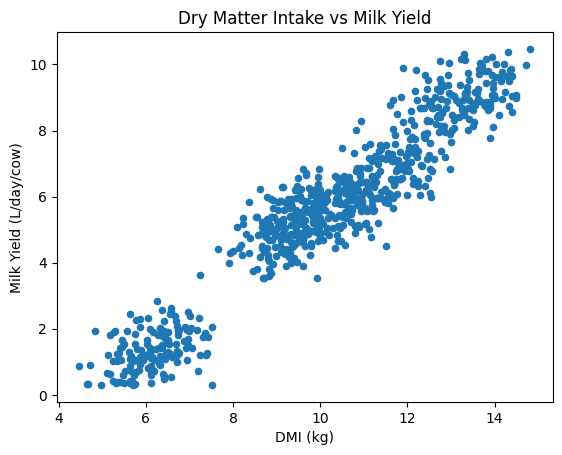

In [8]:
df.plot(
    kind="scatter",
    x="DMI (kg)",
    y="Milk Yield (L/day/cow)",
    title="Dry Matter Intake vs Milk Yield"
)

## Observation 1: Dry Matter Intake

The scatter plot shows a positive association between dry matter intake and milk yield. Higher DMI is generally associated with higher milk yield. This suggests that DMI may be a useful predictor of milk production.

In [9]:
df.groupby("THI Range")["Milk Yield (L/day/cow)"].mean()

THI Range
T0    5.98828
T1    5.57092
T2    5.02904
Name: Milk Yield (L/day/cow), dtype: float64

## Observation 2: THI Range

Average milk yield decreases from approximately 5.99 litres per cow per day at T0 to 5.57 at T1 and 5.03 at T2. This shows an association between THI category and milk yield in the dataset.

In [10]:
df.groupby("Genetic Group")["Milk Yield (L/day/cow)"].mean().sort_values()

Genetic Group
Local     1.369267
HF50      5.089133
HF62.5    5.594600
HF75      6.610000
HF87.5    8.984067
Name: Milk Yield (L/day/cow), dtype: float64

## Observation 3: Genetic Group

Average milk yield differs across the five genetic groups. The HF87.5 group has the highest average milk yield, approximately 8.98 litres per cow per day, while the Local group has the lowest, approximately 1.37 litres. Genetic group may therefore provide useful information for predicting milk yield.

In [11]:
print("Number of unique cows:", df["Animal ID"].nunique())

print("\nRecords per cow:")
print(df["Animal ID"].value_counts().value_counts().sort_index())

Number of unique cows: 50

Records per cow:
count
15    50
Name: count, dtype: int64


## Observation 4: Repeated Records

The dataset contains 750 records from 50 individual cows, with 15 records per cow. This indicates that the dataset includes repeated measurements for each animal. These records should be considered when dividing data for later model validation to reduce the risk of information leakage between training and testing sets.

## 4. Feature Selection

The selected input features are Dry Matter Intake (DMI), THI Range and Genetic Group. Milk Yield (L/day/cow) is the target variable because it is the value the model is intended to predict.

Animal ID is excluded because it identifies individual cows rather than directly describing the selected prediction factors. Replication No. is also excluded from the input features.

In [12]:
model_df = df[
    [
        "Animal ID",
        "DMI (kg)",
        "THI Range",
        "Genetic Group",
        "Milk Yield (L/day/cow)"
    ]
].copy()

model_df.head()


,Animal ID,DMI (kg),THI Range,Genetic Group,Milk Yield (L/day/cow)
0,102,6.91,T0,Local,2.05
1,102,6.61,T0,Local,1.14
2,102,7.31,T0,Local,1.74
3,102,6.75,T0,Local,1.96
4,102,6.42,T0,Local,2.24


In [13]:
print("Modelling dataset shape:", model_df.shape)

print("\nMissing values:")
print(model_df.isnull().sum())

print("\nData types:")
print(model_df.dtypes)

Modelling dataset shape: (750, 5)

Missing values:
Animal ID                 0
DMI (kg)                  0
THI Range                 0
Genetic Group             0
Milk Yield (L/day/cow)    0
dtype: int64

Data types:
Animal ID                   int64
DMI (kg)                  float64
THI Range                  object
Genetic Group              object
Milk Yield (L/day/cow)    float64
dtype: object


## Final DataSet
The selected dataset contains 750 rows and four columns: three input variables and one target variable. Missing values and data types were checked again after feature selection to confirm that the dataset was ready for preprocessing.

In [14]:
model_df = pd.get_dummies(
    model_df,
    columns=["THI Range", "Genetic Group"],
    dtype=int
)

model_df.head()

,Animal ID,DMI (kg),Milk Yield (L/day/cow),THI Range_T0,THI Range_T1,THI Range_T2,Genetic Group_HF50,Genetic Group_HF62.5,Genetic Group_HF75,Genetic Group_HF87.5,Genetic Group_Local
0,102,6.91,2.05,1,0,0,0,0,0,0,1
1,102,6.61,1.14,1,0,0,0,0,0,0,1
2,102,7.31,1.74,1,0,0,0,0,0,0,1
3,102,6.75,1.96,1,0,0,0,0,0,0,1
4,102,6.42,2.24,1,0,0,0,0,0,0,1


THI Range and Genetic Group contain categories instead of numerical values. We had to convert these categories into 0s and 1s so that they can be used by the machine learning model. DMI and Milk Yield were left unchanged because they are already numerical values.

In [15]:
X = model_df.drop(columns=["Milk Yield (L/day/cow)", "Animal ID"])
y = model_df["Milk Yield (L/day/cow)"]
cow_groups = model_df["Animal ID"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Unique cows:", cow_groups.nunique())


Features shape: (750, 9)
Target shape: (750,)
Unique cows: 50


The features have a shape of (750, 9), meaning there are 750 records and 9 input columns. The target has a shape of (750,), meaning there are 750 milk-yield values to be predicted, one for each record.

## 80/20 Grouped Split by Animal ID
Our dataset contains 750 records from 50 individual cows (15 records per cow). To prevent data leakage—ensuring records from the exact same cow do not appear in both training and testing sets—we use `GroupShuffleSplit` grouped by `Animal ID`.

In [16]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
from sklearn.model_selection import GroupShuffleSplit

# Separate features, target and group identifiers
X_full = model_df.drop(columns=["Milk Yield (L/day/cow)"])
y_full = model_df["Milk Yield (L/day/cow)"]
cow_groups = model_df["Animal ID"]

# Perform 80/20 grouped split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X_full, y_full, cow_groups))

# Drop Animal ID from feature matrices before training
X_train = X_full.drop(columns=["Animal ID"]).iloc[train_idx]
X_test = X_full.drop(columns=["Animal ID"]).iloc[test_idx]
y_train = y_full.iloc[train_idx]
y_test = y_full.iloc[test_idx]

print(f"Training cows: {df['Animal ID'].iloc[train_idx].nunique()} cows ({len(X_train)} records)")
print(f"Testing cows: {df['Animal ID'].iloc[test_idx].nunique()} cows ({len(X_test)} records)")

Training cows: 40 cows (600 records)
Testing cows: 10 cows (150 records)


## Feature Scaling
We scale the continuous numerical feature (`DMI (kg)`) using `StandardScaler`. To prevent data leakage, the scaler is fitted strictly on the training set and then applied to transform both the training and testing sets.

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit strictly on X_train, transform both
X_train_scaled[["DMI (kg)"]] = scaler.fit_transform(X_train[["DMI (kg)"]])
X_test_scaled[["DMI (kg)"]] = scaler.transform(X_test[["DMI (kg)"]])

X_train_scaled.head()

,DMI (kg),THI Range_T0,THI Range_T1,THI Range_T2,Genetic Group_HF50,Genetic Group_HF62.5,Genetic Group_HF75,Genetic Group_HF87.5,Genetic Group_Local
0,-1.133991,1,0,0,0,0,0,0,1
1,-1.250218,1,0,0,0,0,0,0,1
2,-0.979021,1,0,0,0,0,0,0,1
3,-1.195979,1,0,0,0,0,0,0,1
4,-1.323829,1,0,0,0,0,0,0,1


## Step 4: Train Multiple Linear Regression Model
We instantiate our first regression model (`LinearRegression`) and train (fit) it using the scaled training features and target variable.

In [19]:
from sklearn.linear_model import LinearRegression

# Initialize and fit the Multiple Linear Regression model
mlr_model = LinearRegression()
mlr_model.fit(X_train_scaled, y_train)

print("Multiple Linear Regression model successfully trained on training data!")

Multiple Linear Regression model successfully trained on training data!


## Step 5: Model Evaluation
We evaluate the trained model on the unseen test cows by generating predictions and calculating Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Coefficient of Determination ($R^2$).

In [20]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Generate predictions on test data
y_pred = mlr_model.predict(X_test_scaled)

# Calculate metrics
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Test R² Score: {test_r2:.4f}")
print(f"Test RMSE: {test_rmse:.4f} Litres/day/cow")
print(f"Test MAE: {test_mae:.4f} Litres/day/cow")

Test R² Score: 0.8571
Test RMSE: 0.6071 Litres/day/cow
Test MAE: 0.4865 Litres/day/cow


##  Cross-Validation and Model Comparison

In [21]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Keep the same cow groups used in the training split
groups_train = cow_groups.iloc[train_idx]

# Use the same five-fold validation strategy for every model
group_cv = GroupKFold(n_splits=5)

# Scale DMI while leaving the other features unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("scale_dmi", StandardScaler(), ["DMI (kg)"])
    ],
    remainder="passthrough"
)

print("Validation setup complete.")
print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Cross-validation folds:", group_cv.get_n_splits())

Validation setup complete.
Training records: 600
Test records: 150
Cross-validation folds: 5



### Observation

The three regression models were prepared for training and evaluation. DMI was standardised to ensure that differences in its numerical scale would not disproportionately affect the linear models. Five-fold GroupKFold cross-validation was selected to evaluate model performance while keeping records belonging to the same cow within the same fold.


## 1: Multiple Linear Regression

In [22]:
# Create a pipeline for Multiple Linear Regression
mlr_model = make_pipeline(
    preprocessor,
    LinearRegression()
)

# Evaluate using five-fold grouped cross-validation
mlr_cv = cross_validate(
    mlr_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

# Train on the full training set and evaluate on the test set
mlr_model.fit(X_train, y_train)
mlr_predictions = mlr_model.predict(X_test)

mlr_test_mae = mean_absolute_error(y_test, mlr_predictions)
mlr_test_rmse = np.sqrt(mean_squared_error(y_test, mlr_predictions))
mlr_test_r2 = r2_score(y_test, mlr_predictions)

print("Multiple Linear Regression")
print("CV MAE:", round(-mlr_cv["test_mae"].mean(), 4))
print("CV RMSE:", round(-mlr_cv["test_rmse"].mean(), 4))
print("CV R²:", round(mlr_cv["test_r2"].mean(), 4))
print("Test MAE:", round(mlr_test_mae, 4))
print("Test RMSE:", round(mlr_test_rmse, 4))
print("Test R²:", round(mlr_test_r2, 4))

Multiple Linear Regression
CV MAE: 0.4644
CV RMSE: 0.5769
CV R²: 0.9542
Test MAE: 0.4865
Test RMSE: 0.6071
Test R²: 0.8571



### Observation

Multiple Linear Regression provides the baseline for comparing the other models. Its cross-validation scores show average performance across folds, while test scores measure performance on held-out cows.


## 2: Random Forest

In [23]:
# Create a Random Forest model
rf_model = make_pipeline(
    preprocessor,
    RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
)

# Evaluate using the same grouped cross-validation
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

# Train and evaluate on the held-out test data
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

rf_test_mae = mean_absolute_error(y_test, rf_predictions)
rf_test_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_test_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regression")
print("CV MAE:", round(-rf_cv["test_mae"].mean(), 4))
print("CV RMSE:", round(-rf_cv["test_rmse"].mean(), 4))
print("CV R²:", round(rf_cv["test_r2"].mean(), 4))
print("Test MAE:", round(rf_test_mae, 4))
print("Test RMSE:", round(rf_test_rmse, 4))
print("Test R²:", round(rf_test_r2, 4))

Random Forest Regression
CV MAE: 0.5515
CV RMSE: 0.6843
CV R²: 0.9352
Test MAE: 0.5538
Test RMSE: 0.7059
Test R²: 0.8068


### Observation
Random Forest combines predictions from multiple decision trees to model potentially complex relationships between feeding factors and milk yield. Its performance is evaluated using the same folds and held-out test set as the other models.

## 3: Ridge Regression

In [24]:
# Create a pipeline with Ridge regularisation
ridge_model = make_pipeline(
    preprocessor,
    Ridge(alpha=0.01)
)

# Evaluate using the same grouped cross-validation
ridge_cv = cross_validate(
    ridge_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

# Train and evaluate on the held-out test data
ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

ridge_test_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_test_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression")
print("Alpha:", 0.01)
print("CV MAE:", round(-ridge_cv["test_mae"].mean(), 4))
print("CV RMSE:", round(-ridge_cv["test_rmse"].mean(), 4))
print("CV R²:", round(ridge_cv["test_r2"].mean(), 4))
print("Test MAE:", round(ridge_test_mae, 4))
print("Test RMSE:", round(ridge_test_rmse, 4))
print("Test R²:", round(ridge_test_r2, 4))

Ridge Regression
Alpha: 0.01
CV MAE: 0.4644
CV RMSE: 0.5769
CV R²: 0.9542
Test MAE: 0.4863
Test RMSE: 0.6068
Test R²: 0.8573



### Observation
Ridge Regression adds a penalty to large coefficients to help control model complexity. Its scores can be compared with the baseline to assess whether regularisation improves prediction performance.

## Compare all three models

In [25]:
comparison = pd.DataFrame([
    {
        "Model": "Multiple Linear Regression",
        "CV MAE": -mlr_cv["test_mae"].mean(),
        "CV RMSE": -mlr_cv["test_rmse"].mean(),
        "CV R²": mlr_cv["test_r2"].mean(),
        "Test MAE": mlr_test_mae,
        "Test RMSE": mlr_test_rmse,
        "Test R²": mlr_test_r2
    },
    {
        "Model": "Ridge Regression",
        "CV MAE": -ridge_cv["test_mae"].mean(),
        "CV RMSE": -ridge_cv["test_rmse"].mean(),
        "CV R²": ridge_cv["test_r2"].mean(),
        "Test MAE": ridge_test_mae,
        "Test RMSE": ridge_test_rmse,
        "Test R²": ridge_test_r2
    },
    {
        "Model": "Random Forest Regression",
        "CV MAE": -rf_cv["test_mae"].mean(),
        "CV RMSE": -rf_cv["test_rmse"].mean(),
        "CV R²": rf_cv["test_r2"].mean(),
        "Test MAE": rf_test_mae,
        "Test RMSE": rf_test_rmse,
        "Test R²": rf_test_r2
    }
])

# Round the results for easier comparison
comparison = comparison.round(4)

comparison

,Model,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²
0,Multiple Linear Regression,0.4644,0.5769,0.9542,0.4865,0.6071,0.8571
1,Ridge Regression,0.4644,0.5769,0.9542,0.4863,0.6068,0.8573
2,Random Forest Regression,0.5515,0.6843,0.9352,0.5538,0.7059,0.8068



### Observation
The comparison table shows how each model performs across cross-validation folds and on unseen test data. Lower MAE and RMSE indicate smaller prediction errors, while higher \(R^2\) indicates that the model explains more variation in milk yield. The best model should be selected based on the results, not simply because it sounds more advanced.